**ФИО студента:** Михалева Софья Дмитриевна

**Задание:** inpainting

**Группа:** J4251

**Дата сдачи:** 26.11.2026

## Настройка окружения

- Данные: data/inpainting_cube_missed_data.npy
- Веса для сдачи: models/inpainting_ensemble.pt файл содержит все пять чекпойнтов.
- Отдельные веса, которые ноутбук использует при отсутствии общего файла:
  - runs/inpainting_unet/best.pt — исходный односрезовый U-Net;
  - runs/inpainting_gan/best.pt — генератор GAN;
  - runs/inpainting_unet_up/best.pt — односрезовый U-Net с билинейным апсемплингом;
  - runs/inpainting_unet_wide16_original_ep80/best.pt — _wide16, seed 19, чекпойнт 59-й эпохи;
  - runs/inpainting_unet_wide16_original_ep80_s23/best.pt — _wide16, seed 23, чекпойнт 63-й эпохи.
- Итоговая модель — смесь 50/50 среднего трех односрезовых моделей и среднего двух _wide16. Для тестирования и восстановления реального пропуска используются одни и те же чекпойнты, обученные на train-блоке и выбранные по валидации.
- При запуске ноутбук загружает готовые веса. Истории hist.json используются для графиков, если они доступны

In [ ]:
import json
import os
import subprocess
import sys
from pathlib import Path

# Ищем корень проекта при запуске из корня или из папки notebooks
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'README.md').is_file() and (path / 'SeismicUtils.py').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Откройте ноутбук внутри репозитория cv_seysmorazvedka.')
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import Rectangle
from torch.utils.data import DataLoader

import SeismicUtils
import seismic_lib as sl
from compare import model_pred
from inpainting_wide import WideTunnelPatches
from inpainting_wide_compare import MatchedWindows, evaluate, predict_groups
from train_unet import SPLITS

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
BATCH_SIZE = 4
SEED, COUNT = 42, 400
DATA = Path('data/inpainting_cube_missed_data.npy')
OUTPUT = Path('results/inpainting_restored_original_ep80_two_seeds.npy')
BUNDLE = Path('models/inpainting_ensemble.pt')
TEST_REPORT = Path('results/inpainting_wide_original_ep80_two_seeds_test.json')
report = json.loads(TEST_REPORT.read_text())
baseline_paths = report['baseline_checkpoints']
wide_paths = report['wide_checkpoints']
use_bundle = BUNDLE.is_file()
weight_paths = [BUNDLE] if use_bundle else [*baseline_paths, *wide_paths]
missing = [str(p) for p in map(Path, [DATA, *weight_paths]) if not p.is_file()]
if missing:
    raise FileNotFoundError('Нужны локальные файлы: ' + ', '.join(missing))
print('Устройство', DEVICE)

Устройство cuda


## Данные

- **Входной файл** — data/inpainting_cube_missed_data.npy, массив float32 размером 580 × 951 × 462
- **Оси** — axis0 и axis1 латеральные, axis2 соответствует глубине z
- **Реальный пропуск** — cube[:, 368:581, 179:282] Это туннель шириной 213 трасс и глубиной 103 отсчета, проходящий через все 580 срезов axis0. Всего в нем 12724620 вокселов. После заполнения значения вне этой области сохраняются бит в бит
- **Нормировка** — из амплитуд вычитается среднее и результат делится на стандартное отклонение. Во всех пяти чекпойнтах используются mean = 0.4999571740627289 и std = 0.038330044597387314, рассчитанные по известным вокселам каждого второго среза исходного куба. При инференсе предсказания возвращаются в исходный масштаб.

Модели обучались на одном сейсмокубе с самосупервизией. В известной области создавались искусственные пропуски 213 × 103, а исходные амплитуды внутри них служили эталоном. Разбиение по axis0 задано полуинтервалами Python:

| Выборка | Срезы |
|---|---|
| Обучение | [0, 400) |
| Валидация | [416, 496) |
| Тест | [500, 580) |

Форма и тип (580, 951, 462) float32
Скрыто вокселов 12724620


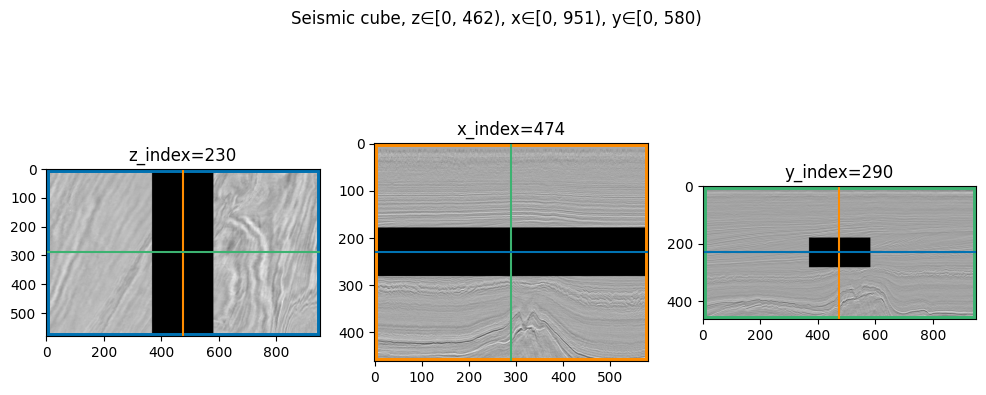

In [2]:
cube = np.load(DATA, mmap_mode='r')
real_mask = sl.hole_mask('inpainting', (1, *cube.shape[1:]))
print('Форма и тип', cube.shape, cube.dtype)
print('Скрыто вокселов', int(real_mask.sum()) * cube.shape[0])
SeismicUtils.visualize_three_plots(cube, z_index=230, x_index=474, y_index=290)

## Модель

У всех участников есть кодировщик и декодер U-Net со skip connections. Блок DoubleConv состоит из двух последовательностей Conv2d 3 × 3 -> BatchNorm2d -> ReLU. Кодировщик уменьшает пространственное разрешение через MaxPool2d с шагом 2, а декодер восстанавливает его и конкатенирует признаки с соответствующего уровня кодировщика. Финальная свертка 1×1 выдает один канал амплитуд центрального среза

| Участник | Вход (каналы × axis1 × z) | Уровни | Базовые каналы | Апсемплинг | Параметры для инференса | Вес в итоговой смеси |
|---|---|---:|---:|---|---:|---:|
| Исходный U-Net | 2 × 352 × 192 | 4 | 32 | ConvTranspose2d | 7 762 753 | 1/6 |
| Генератор GAN | 2 × 352 × 192 | 4 | 32 | ConvTranspose2d | 7 762 753 | 1/6 |
| U-Net _up | 2 × 352 × 192 | 4 | 32 | Билинейная интерполяция + свертка 3 × 3 | 8 633 153 | 1/6 |
| _wide16, seed 19 | 6 × 384 × 256 | 5 | 16 | ConvTranspose2d | 7 779 041 | 1/4 |
| _wide16_s23, seed 23 | 6 × 384 × 256 | 5 | 16 | ConvTranspose2d | 7 779 041 | 1/4 |

В первом подансамбле два входных канала — один сейсмический срез и бинарная маска. Во втором подансамбле пять каналов сигнала соответствуют срезам y−2, y−1, y, y+1, y+2, шестой канал содержит маску. Скрытые вокселы обнуляются в нормированном входе. Свертки 2.5D-группы двумерные, а соседние срезы поступают в них как каналы. У четырехуровневых моделей каналы кодировщика — 32, 64, 128, 256, в узком месте — 512. У пятиуровневых — 16, 32, 64, 128, 256, в узком месте также 512. Суммарно при инференсе используются 39716741 параметр

### Исходный односрезовый U-Net

Первый вариант использует четыре уровня U-Net, 32 базовых канала и транспонированные свертки. Вход — один срез и маска, выход — восстановленный центральный срез. Loss объединяет L1 внутри пропуска и ошибку пространственных градиентов с весом 0,5. Обучение шло 80 эпох по 3000 патчей. Для теста выбраны веса 54-й эпохи по среднему Пирсону на валидации.

На основном тесте глобальный Пирсон вырос с 0,1027 у линейной интерполяции до 0,3417 у U-Net с TTA. На следующем шаге прогноз U-Net усреднили с прогнозами GAN и _up. Далее эту группу смешали с предсказаниями _wide16

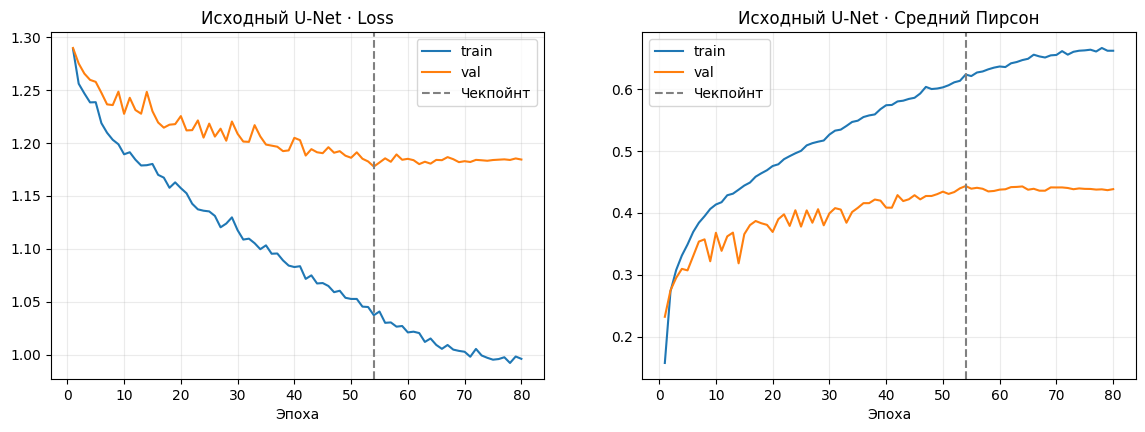

In [3]:
base_history = json.loads(Path('models/inpainting_history.json').read_text())['holdout']
base_hist = base_history['hist']
base_epochs = np.arange(1, len(base_hist['train_r']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric, title in zip(axes, ('loss', 'r'), ('Loss', 'Средний Пирсон')):
    for split in ('train', 'val'):
        ax.plot(base_epochs, base_hist[f'{split}_{metric}'], label=split)
    ax.axvline(base_history['best_epoch'], color='gray', linestyle='--', label='Чекпойнт')
    ax.set(xlabel='Эпоха', title=f'Исходный U-Net · {title}')
    ax.legend()
    ax.grid(alpha=0.25)
plt.show()

В первые 15-20 эпох средний Пирсон на валидации растет быстрее всего. Затем рост замедляется, и к 54-й эпохе метрика достигает 0,443, после чего держится примерно на том же уровне. При этом Пирсон на обучении продолжает расти, а train loss снижается. Увеличивающийся разрыв между train и val показывает, что дальнейшее улучшение на обучающих патчах почти не переносится на валидацию

In [4]:
if use_bundle:
    (baseline, baseline_cfg, norm), (wide, wide_cfg, wide_norm) = sl.load_inpainting_bundle(BUNDLE, DEVICE)
    print('Веса ансамбля', BUNDLE)
else:
    baseline, baseline_cfg, norm = sl.load_inpainting_ensemble(baseline_paths, DEVICE)
    wide, wide_cfg, wide_norm = sl.load_inpainting_ensemble(wide_paths, DEVICE)
    for path in [*baseline_paths, *wide_paths]:
        checkpoint = torch.load(path, map_location='cpu', weights_only=True)
        print(f"{path}: эпоха {checkpoint['epoch']}")
    del checkpoint
assert wide_cfg['wide_tunnel'] and wide_norm == norm
print('Нормировка', norm)
print('Параметров', sum(p.numel() for model in (baseline, wide) for p in model.parameters()))

Веса ансамбля runs\submission\inpainting_ensemble.pt
Нормировка Norm(mean=0.4999571740627289, std=0.038330044597387314)
Параметров 39716741


## Обучение модели

**Односрезовые модели.** Для исходного U-Net и _up использовались 80 эпох по 3000 случайных патчей, batch 16, AdamW с максимальным learning rate 0.001, weight decay 0.0001 и OneCycleLR. Функция потерь объединяла L1 по искусственному пропуску и L1 ошибки пространственных разностей вдоль латерали и глубины с весом 0.5. Генератор GAN стартовал с весов исходного U-Net и дообучался 20 эпох с PatchGAN-дискриминатором, hinge loss и весом состязательного слагаемого 0.01. Learning rate для генератора и дискриминатора составлял 0.0001 и 0.0002 соответственно. В инференсе используется генератор

**Две _wide16.** Каждая обучалась с нуля 80 эпох по 1600 случайных патчей, batch 4, AdamW с начальным learning rate 0.001, weight decay 0.0001 и CosineAnnealingLR. Отличался seed — 19 или 23. Искусственная дыра сдвигалась до 24 отсчетов по каждой оси патча. Использовались поперечные срезы из известной области, отражение по латерали, обратный порядок входных срезов, смена полярности и случайное усиление амплитуды exp(U(−0.2, 0.2))

У _wide16 входная маска объединяет искусственный и реальный пропуски, если оба попадают в окно. Маска для обучения включает только искусственный пропуск, который целиком лежит в известной части куба. Функция потерь L1 + (1 − Pearson) вычисляется по этой маске. Валидация при обучении использует 152 примера на глубине 179:282, с пропусками в диапазонах 100:313 и 640:853 по axis1

| Модель | Эпоха чекпойнта | Файл |
|---|---:|---|
| Исходный U-Net | 54 | runs/inpainting_unet/best.pt |
| Генератор GAN | 3 | runs/inpainting_gan/best.pt |
| U-Net _up | 59 | runs/inpainting_unet_up/best.pt |
| _wide16, seed 19 | 59 | runs/inpainting_unet_wide16_original_ep80/best.pt |
| _wide16, seed 23 | 63 | runs/inpainting_unet_wide16_original_ep80_s23/best.pt |

Режим --wide-tunnel выбирает чекпойнт по среднему Пирсону на 152 валидационных пропусках. Для сравнения составов смеси использовались 400 пропусков на том же валидационном блоке

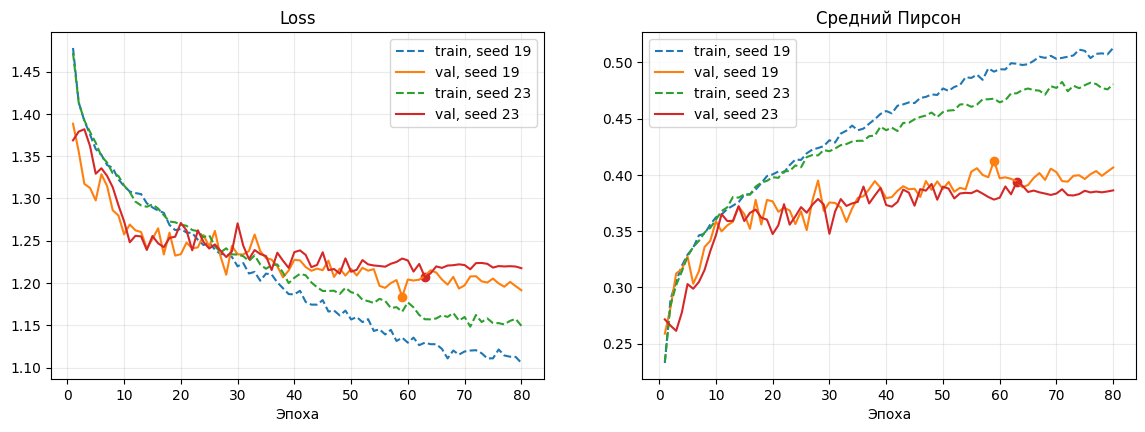

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
available = False
for seed, path in zip((19, 23), wide_paths):
    history_path = Path(path).with_name('hist.json')
    if not history_path.is_file():
        continue
    available = True
    hist = json.loads(history_path.read_text())['hist']
    best = int(np.argmax(hist['val_r']))
    epochs = np.arange(1, len(hist['val_r']) + 1)
    for ax, metric, title in zip(axes, ('loss', 'r'), ('Loss', 'Средний Пирсон')):
        ax.plot(epochs, hist['train_' + metric], '--', label=f'train, seed {seed}')
        line, = ax.plot(epochs, hist['val_' + metric], label=f'val, seed {seed}')
        ax.scatter(best + 1, hist['val_' + metric][best], color=line.get_color())
        ax.set(xlabel='Эпоха', title=title)
if available:
    for ax in axes:
        ax.legend()
        ax.grid(alpha=0.25)
    plt.show()
else:
    plt.close(fig)
    print('Локальные hist.json отсутствуют.')

У обеих моделей основной прирост на валидации происходит в первые 20 эпох. Дальше метрика колеблется, но лучшие значения получены заметно позже: 0,413 на 59-й эпохе для seed 19 и 0,394 на 63-й эпохе для seed 23. Эти чекпойнты выбраны по среднему Пирсону на валидации

### Примеры обучающих окон _wide16

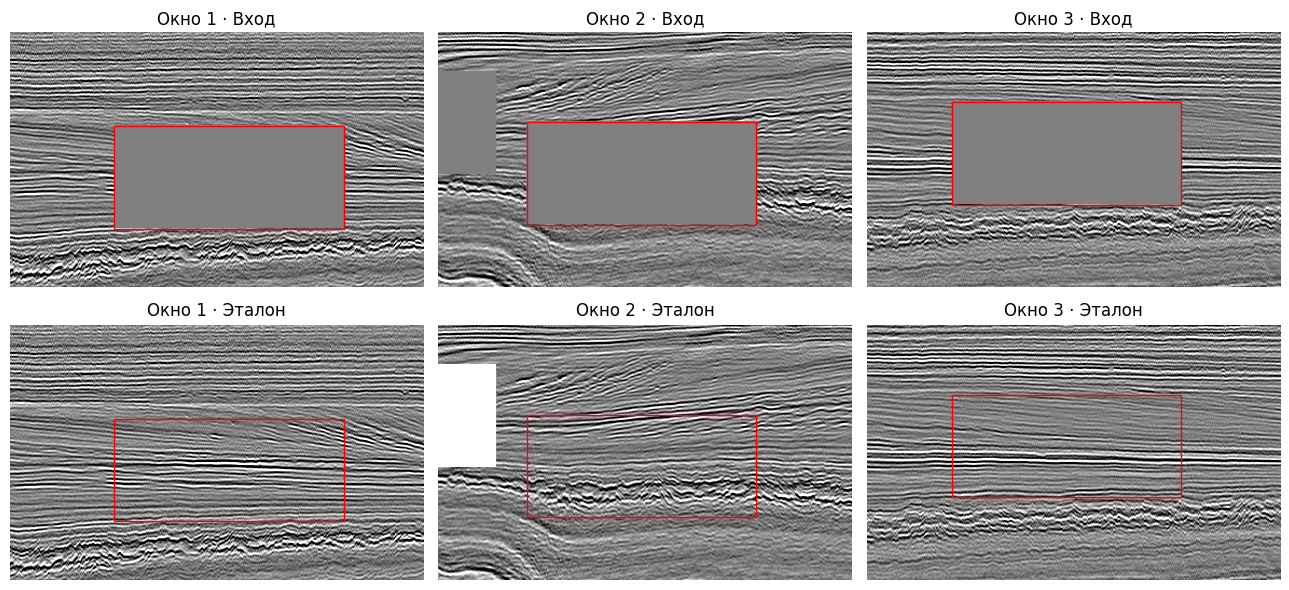

In [6]:
train_rows = SPLITS['inpainting'][0]
train_examples = WideTunnelPatches(cube, real_mask, norm, train_rows, 3, 19, True,
                                   extra_augmentation=True)
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for col in range(len(train_examples)):
    sample, truth, supervision = train_examples[col]
    rows, depths = np.where(supervision[0].numpy().astype(bool))
    for ax, image, label in zip(axes[:, col], (sample[2], truth[0]), ('Вход', 'Эталон')):
        ax.imshow(image.numpy().T, cmap='gray', vmin=-2.5, vmax=2.5, aspect='auto')
        ax.add_patch(Rectangle((rows.min() - 0.5, depths.min() - 0.5),
                               np.ptp(rows) + 1, np.ptp(depths) + 1, fill=False, edgecolor='red'))
        ax.set_title(f'Окно {col + 1} · {label}')
        ax.set_axis_off()
fig.tight_layout()
plt.show()

## Тестирование модели

Сравнение выполнено с TTA на **одних и тех же 400 искусственных пропусках** в тестовом блоке [500, 580), seed 42. Для каждого пропуска сохранялись координаты скрытых вокселов и эталон, а входное окно формировалось под архитектуру каждой группы. R_mean — средний Пирсон по отдельным пропускам. R_global — единый Пирсон по объединённым скрытым вокселам всех пропусков.

| Вариант | R_mean с TTA | R_global с TTA |
|---|---:|---:|
| Линейная интерполяция | 0,1100 | 0,1027 |
| Исходный U-Net | 0,3318 | 0,3417 |
| Ансамбль трех односрезовых моделей | 0,3435 | 0,3536 |
| Смесь с одной 20-эпоховой _wide16 | 0,3705 | 0,3793 |
| Смесь с двумя 20-эпоховыми _wide16 | 0,3722 | 0,3809 |
| Смесь с _wide16, обученными 80 и 20 эпох | 0,3819 | 0,3909 |
| Смесь с одной 80-эпоховой _wide16 | 0,3841 | 0,3932 |
| **Смесь с двумя 80-эпоховыми _wide16** | **0,3862** | **0,3959** |

Итоговая смесь дала **+0,0151** относительно смеси с двумя 20-эпоховыми моделями и **+0,0542** относительно исходного U-Net. На 400 валидационных пропусках итоговая смесь получила глобальный Пирсон **0,4916**. Для реального туннеля эталон недоступен

In [7]:
test_rows = SPLITS['inpainting'][2]
test_ds = MatchedWindows(cube, real_mask, norm, test_rows, COUNT, 2000 + SEED)
scores = evaluate(DataLoader(test_ds, batch_size=BATCH_SIZE), baseline, wide, norm, DEVICE)
print(f"{'Вариант':<18} {'R_mean':>10} {'R_global':>10}")
for name, values in scores.items():
    print(f"{name:<18} {values['pearson_mean_tta']:10.4f} {values['pearson_global_tta']:10.4f}")
for metric in ('pearson_mean_tta', 'pearson_global_tta'):
    np.testing.assert_allclose(scores['blend_two_seeds'][metric],
                               report['results']['blend_two_seeds'][metric], atol=1e-4)

Вариант                R_mean   R_global
baseline               0.3435     0.3536
wide_first             0.3672     0.3743
wide_ensemble          0.3790     0.3873
blend_first            0.3841     0.3932
blend_two_seeds        0.3862     0.3959


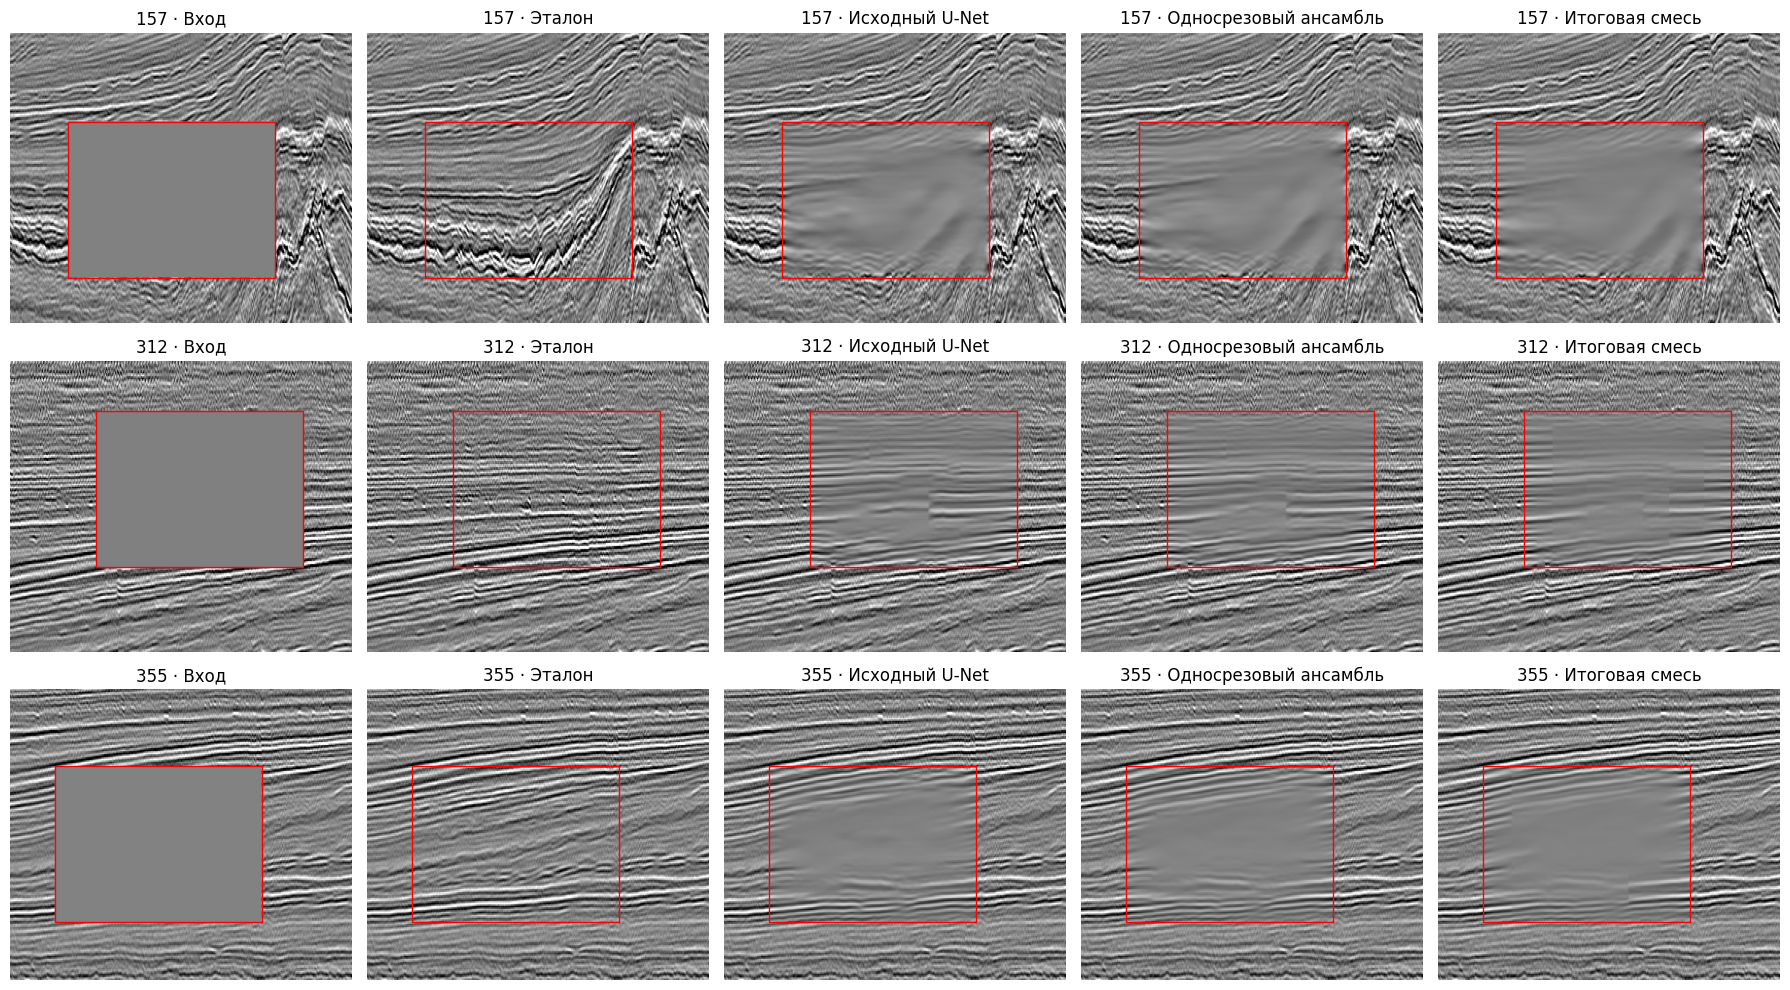

In [8]:
# Сравнение моделей на трех фиксированных тестовых окнах.
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
with torch.inference_mode():
    for row, idx in enumerate((157, 312, 355)):
        x, target, mask, wx, wmask = (torch.as_tensor(v, device=DEVICE).unsqueeze(0) for v in test_ds[idx])
        coarse, _, average = predict_groups(baseline, wide, norm, x, target, mask, wx, wmask)
        single = model_pred(baseline.models[0], x, 'inpainting', 1, True)[mask]
        known = norm.inv(x[0, 0]).cpu().numpy()
        gap = mask[0, 0].cpu().numpy()
        yy, zz = np.where(gap)
        sections = [known]
        for values in (target, single, coarse, (coarse + average) / 2):
            section = known.copy()
            section[gap] = norm.inv(values).cpu().numpy().ravel()
            sections.append(section)
        lo, hi = np.percentile(known[~gap], (1, 99))
        titles = ('Вход', 'Эталон', 'Исходный U-Net', 'Односрезовый ансамбль', 'Итоговая смесь')
        for ax, section, title in zip(axes[row], sections, titles):
            ax.imshow(section.T, cmap='gray', vmin=lo, vmax=hi, aspect='auto')
            ax.add_patch(Rectangle((yy.min() - 0.5, zz.min() - 0.5),
                                   np.ptp(yy) + 1, np.ptp(zz) + 1, fill=False, edgecolor='red'))
            ax.set_title(f'{idx} · {title}')
            ax.set_axis_off()
fig.tight_layout()
plt.show()

## Инференс модели

Штатный infer.py использует те же пять чекпойнтов и смесь 50/50. Известные значения за пределами реального тоннеля сохраняются

In [9]:
# Освобождаем модели перед запуском штатного инференса.
del baseline, wide, x, target, mask, wx, wmask, coarse, average, values
if torch.cuda.is_available():
    torch.cuda.empty_cache()

model_args = ['--inpainting-bundle', str(BUNDLE)] if use_bundle else [
    '--ensemble', *baseline_paths, '--blend-wide', *wide_paths,
]
command = [sys.executable, '-u', 'infer.py', '--task', 'inpainting',
           *model_args, '--bs', str(BATCH_SIZE), '--out', str(OUTPUT)]
result = subprocess.run(command, check=True, capture_output=True, text=True)
print(result.stdout)
restored = np.load(OUTPUT, mmap_mode='r')

config {'base': 32, 'k': 1, 'stride': 1, 'up_mode': 'transpose', 'context_z': None, 'dip_guided': False, 'wide_tunnel': False, 'joint_members': None} norm Norm(mean=0.4999571740627289, std=0.038330044597387314)
Baseline ensemble finished; reconstructing with both wide models
inference 49s
OK: shape (580, 951, 462), hole voxels 12724620, zeros left in hole 0
known: mean 0.5000 std 0.0383 | filled: mean 0.5002 std 0.0131
saved results\inpainting_restored_original_ep80_two_seeds.npy



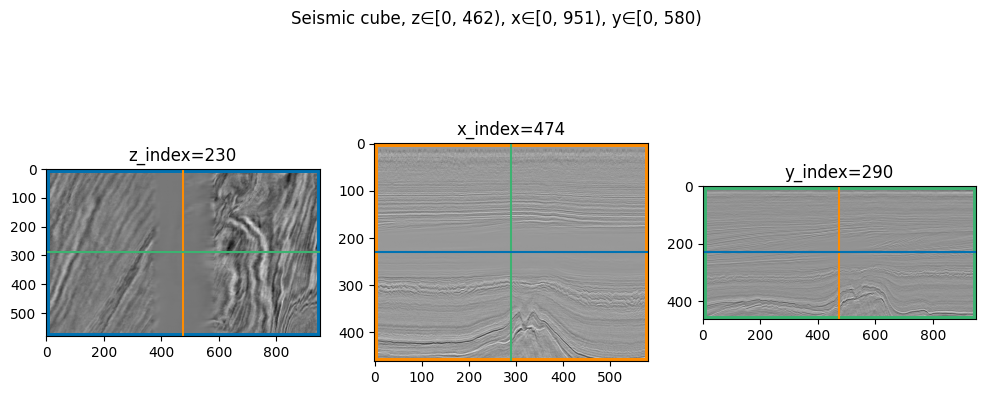

In [10]:
SeismicUtils.visualize_three_plots(restored, z_index=230, x_index=474, y_index=290)

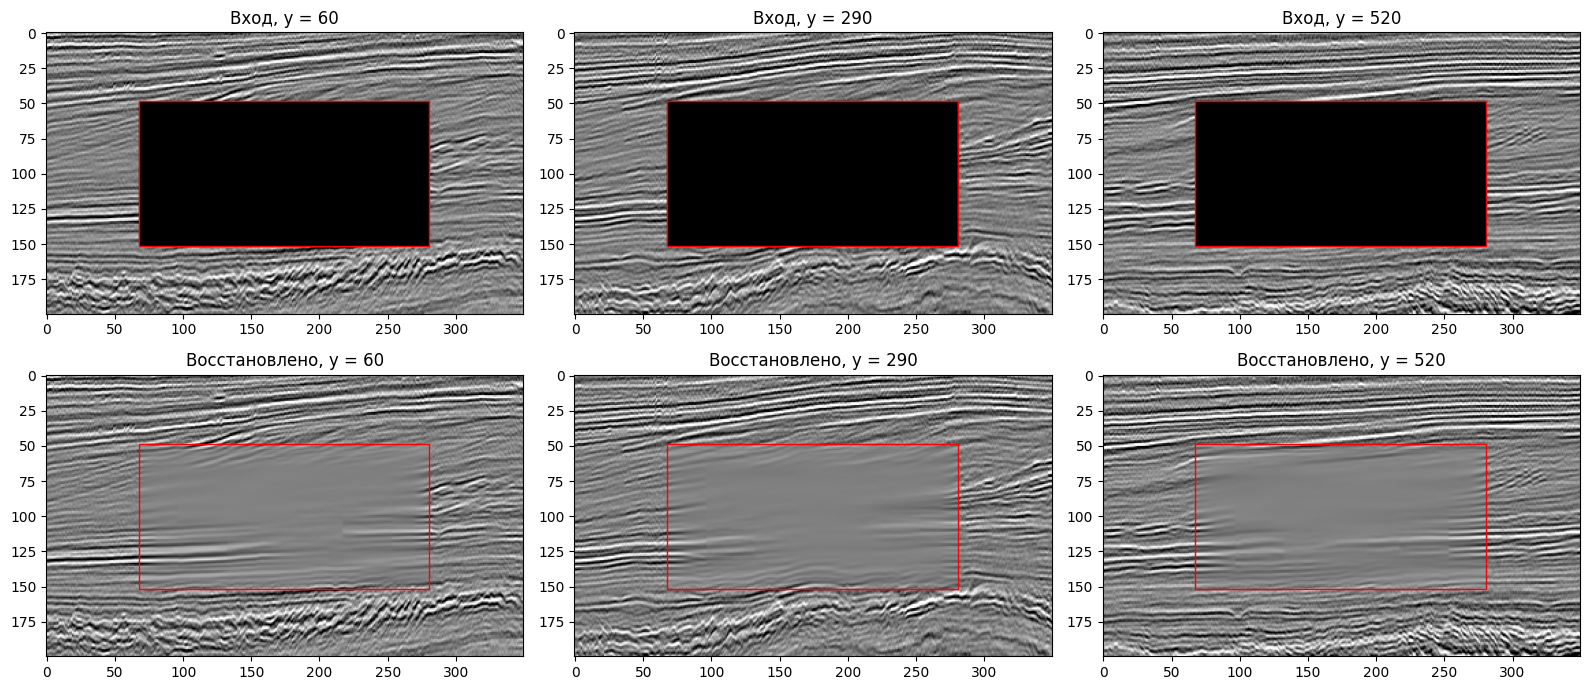

In [11]:
x0, x1, z0, z1 = 300, 650, 130, 330
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for col, row in enumerate((60, 290, 520)):
    lo, hi = np.percentile(cube[row][~real_mask[0]], (1, 99))
    for ax, array, title in zip(axes[:, col], (cube, restored), ('Вход', 'Восстановлено')):
        ax.imshow(array[row, x0:x1, z0:z1].T, cmap='gray', vmin=lo, vmax=hi, aspect='auto')
        ax.add_patch(Rectangle((368 - x0 - 0.5, 179 - z0 - 0.5), 213, 103, fill=False, edgecolor='red'))
        ax.set_title(f'{title}, y = {row}')
fig.tight_layout()
plt.show()

## Блок сохранения артефактов

Куб сохраняется в results/inpainting_restored_original_ep80_two_seeds.npy. Проверяем форму, тип, конечность значений, заполнение тоннеля и побитовое совпадение известных вокселов

In [12]:
assert restored.shape == cube.shape and restored.dtype == cube.dtype
known = ~real_mask[0]
for row in range(cube.shape[0]):
    assert np.isfinite(restored[row]).all()
    assert not (restored[row][real_mask[0]] == 0).any()
    np.testing.assert_array_equal(restored[row][known].view(np.uint32),
                                  cube[row][known].view(np.uint32))
print(f'Проверено {cube.shape[0]} срезов. Размер файла {OUTPUT.stat().st_size:,} байт.')

Проверено 580 срезов. Размер файла 1,019,319,968 байт.
